In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tsn_scheduling_problem import TSNScheduling
from usecase_generator import UsecaseGenerator
from env import TSNDefragEnv

%matplotlib inline

In [2]:
# ── 1. Create problem + usecase ──────────────────────────────────────
CONFIG_FILE = "uc_config.cfg"

problem = TSNScheduling(problem_definition=CONFIG_FILE)
usecase = problem.instantiate()

with problem.use_instance(usecase):
    print(f"Ports : {problem.n_ports}")
    print(f"Streams: {problem.n_streams}")
    print(f"Macro-cycle (ns): {problem.macro_cycle}")
    print(f"Nodes : {problem.n_nodes}")
    print()
    # show first stream's path
    streams = problem.streams
    for i, s in enumerate(streams[:3]):
        path = s.get("pathLists", [[]])[0] if "pathLists" in s else []
        print(f"  stream {i}: interval={s['interval']} ns, "
              f"path (port ids)={path}")

Ports : 96
Streams: 5
Macro-cycle (ns): 100000
Nodes : 36

  stream 0: interval=100000 ns, path (port ids)=[53, 45, 39, 1, 17, 27]
  stream 1: interval=100000 ns, path (port ids)=[75, 69, 59, 2, 37, 48]
  stream 2: interval=100000 ns, path (port ids)=[74, 65, 59, 4, 78, 92]


In [3]:
# ── 2. Create environment ────────────────────────────────────────────
env = TSNDefragEnv(
    problem=problem,
    usecase=usecase,
    gap_threshold_ratio=0.01,
    move_penalty=0.01,
    max_edges=200,
)

print(f"Action space  : {env.action_space.shape}")
print(f"Obs space keys: {list(env.observation_space.spaces.keys())}")
print(f"Cycle (ns)    : {env.cycle_ns}")
print(f"N streams     : {env.n_streams}")
print(f"N ports       : {env.n_ports}")
print()
print("Stream info (first 3):")
for i, si in enumerate(env.stream_info[:3]):
    print(f"  [{i}] path={si['path']}, interval={si['interval_ns']} ns, "
          f"hops={len(si['hop_delays'])}, hop_cost={si['total_hop_cost_ns']:.1f} ns")

Action space  : (5, 96)
Obs space keys: ['adjacency_matrix', 'port_metrics', 'stream_features', 'stream_placement']
Cycle (ns)    : 100000
N streams     : 5
N ports       : 96

Stream info (first 3):
  [0] path=[53, 45, 39, 1, 17, 27], interval=100000 ns, hops=5, hop_cost=210302.0 ns
  [1] path=[75, 69, 59, 2, 37, 48], interval=100000 ns, hops=5, hop_cost=215714.0 ns
  [2] path=[74, 65, 59, 4, 78, 92], interval=100000 ns, hops=5, hop_cost=207486.0 ns


In [4]:
# ── 3. Reset and inspect observation ─────────────────────────────────
obs, info = env.reset()

print("Observation shapes:")
for k, v in obs.items():
    print(f"  {k:20s} → {v.shape}  dtype={v.dtype}")

print(f"\nInitial gap count: {env._count_gaps()}")

print("\nStream features (first 5)  [offset, duration, period, latency, hop_cost]:")
print(obs["stream_features"][:5])

print("\nPort metrics (non-zero rows only)  [util, useless_ratio, avg_useful]:")
pm = obs["port_metrics"]
for pidx in range(pm.shape[0]):
    if pm[pidx].any():
        print(f"  port {pidx}: {pm[pidx]}")

print(f"\nAdjacency edges (first 10 columns):")
adj = obs["adjacency_matrix"]
valid = adj[0] >= 0
print(f"  total edges: {valid.sum()}")
print(f"  sample: {list(zip(adj[0, :10].tolist(), adj[1, :10].tolist()))}")

Observation shapes:
  stream_placement     → (5, 96)  dtype=float32
  stream_features      → (5, 5)  dtype=float32
  port_metrics         → (96, 3)  dtype=float32
  adjacency_matrix     → (2, 200)  dtype=int64

Initial gap count: 32

Stream features (first 5)  [offset, duration, period, latency, hop_cost]:
[[0.       0.020504 1.       1.       2.10302 ]
 [0.       0.031328 1.       1.       2.15714 ]
 [0.       0.014872 1.       1.       2.07486 ]
 [0.       0.016896 1.       1.       2.08498 ]
 [0.       0.012584 1.       1.       2.06342 ]]

Port metrics (non-zero rows only)  [util, useless_ratio, avg_useful]:
  port 0: [0.0205 0.     0.9795]
  port 1: [0.03133 0.      0.96867]
  port 2: [0.01258 0.      0.98742]
  port 3: [0.01487 0.      0.98513]
  port 16: [0.0205 0.     0.9795]
  port 18: [0.0169  0.      0.49155]
  port 24: [0.01689  0.       0.491555]
  port 26: [0.0205 0.     0.9795]
  port 33: [0.0169 0.     0.9831]
  port 36: [0.03133 0.      0.96867]
  port 38: [0.03308    

In [5]:
# ── 4. Random step ──────────────────────────────────────────────────
action = env.action_space.sample()
print(f"Action shape: {action.shape}")
print(f"Action range: [{action.min():.3f}, {action.max():.3f}]")

obs2, reward, term, trunc, info = env.step(action)

print(f"\nReward      : {reward:.6f}")
print(f"Old gaps    : {info['old_gaps']}")
print(f"New gaps    : {info['new_gaps']}")
print(f"Delta frag  : {info['delta_frag']:.6f}")
print(f"Streams moved: {info['n_moved']}")

Action shape: (5, 96)
Action range: [0.009, 1.996]

Reward      : 0.021250
Old gaps    : 32
New gaps    : 31
Delta frag  : 0.031250
Streams moved: 1


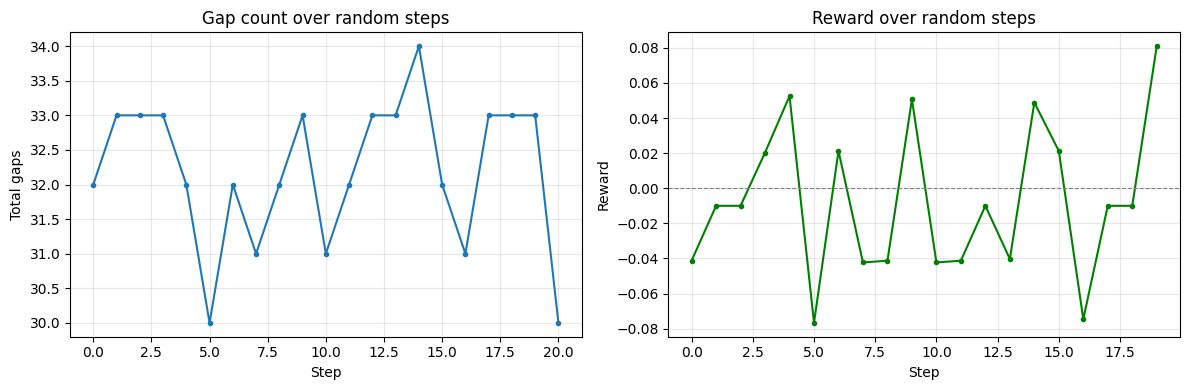

In [6]:
# ── 5. Multi-step loop ──────────────────────────────────────────────
obs, _ = env.reset()
gap_history = [env._count_gaps()]
reward_history = []

for step in range(20):
    action = env.action_space.sample()
    obs, reward, _, _, info = env.step(action)
    gap_history.append(info["new_gaps"])
    reward_history.append(reward)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(gap_history, marker="o", markersize=3)
ax1.set_xlabel("Step")
ax1.set_ylabel("Total gaps")
ax1.set_title("Gap count over random steps")
ax1.grid(True, alpha=0.3)

ax2.plot(reward_history, marker="o", markersize=3, color="green")
ax2.set_xlabel("Step")
ax2.set_ylabel("Reward")
ax2.set_title("Reward over random steps")
ax2.axhline(0, color="gray", ls="--", lw=0.8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

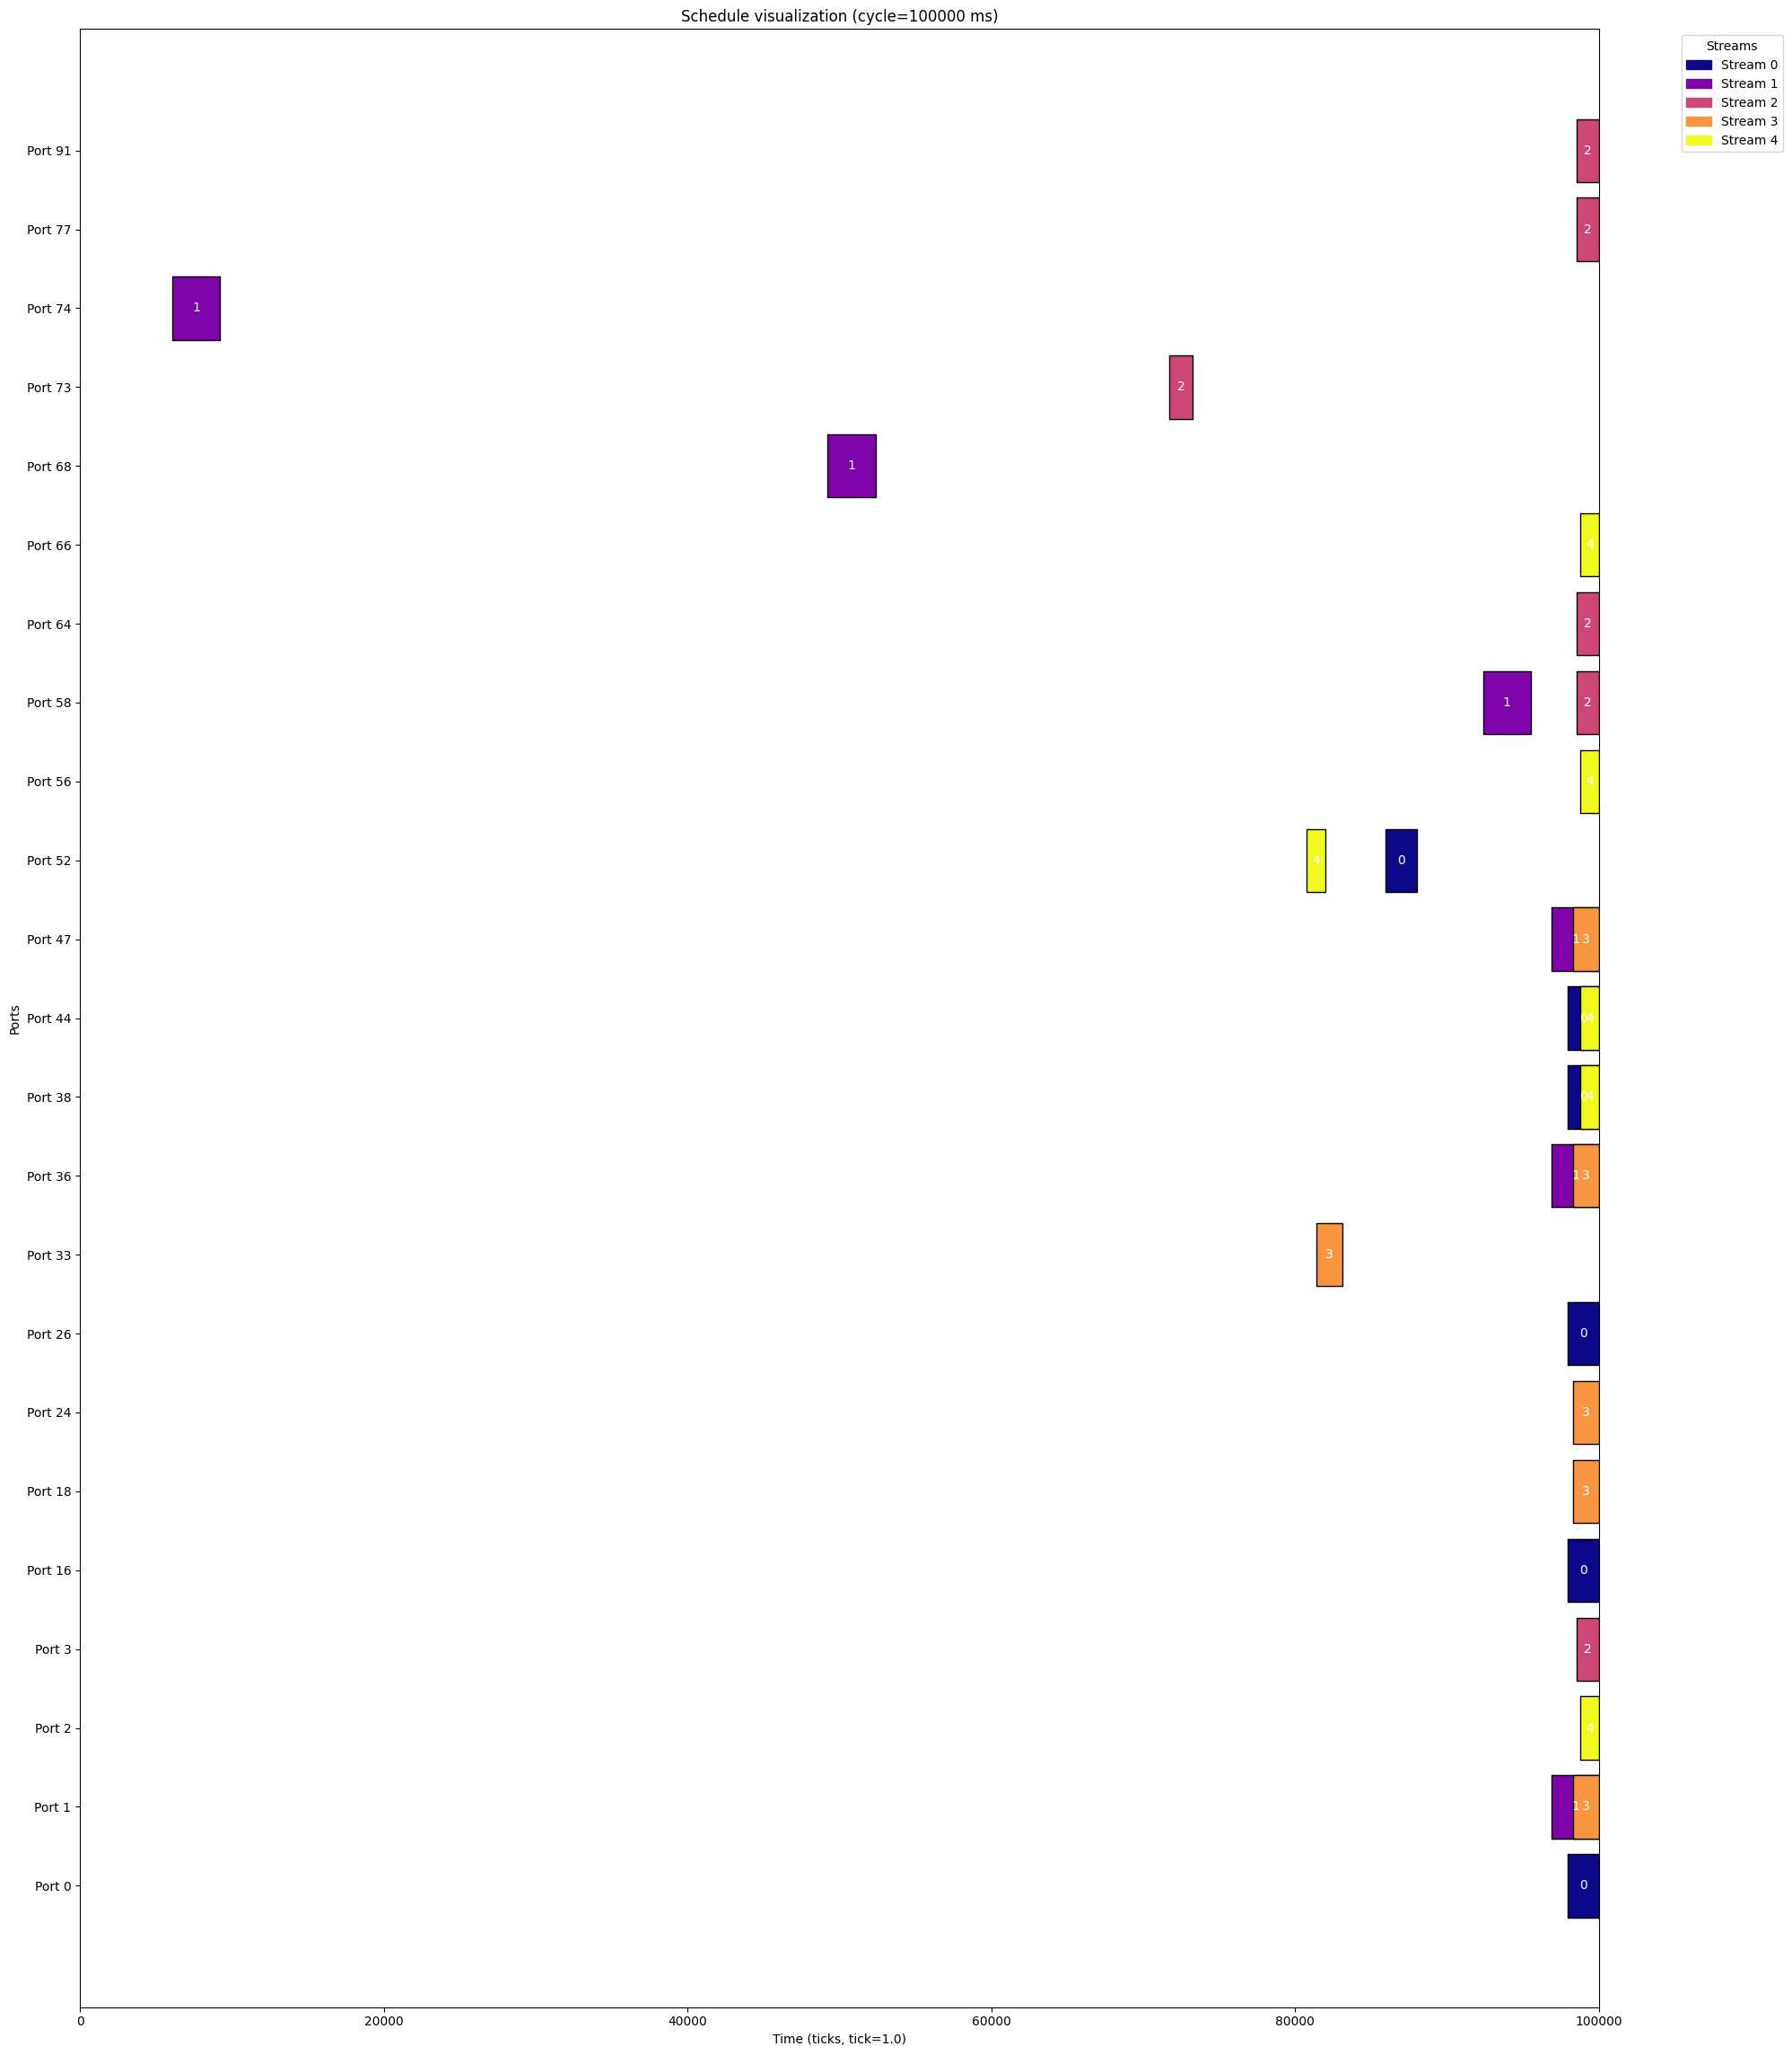

In [7]:
# ── 6. Visualise current schedule ────────────────────────────────────
fig = env.render()
plt.show()